# Variables antitéticas

## Introducción: el problema de las muestras finitas

Una $N(0,1)$ es perfectamente simétrica alrededor de cero. En teoría:

- La mitad de los valores son negativos y la mitad positivos.
- El promedio de los negativos es $-\sqrt{2/\pi} = -0.7979$ y el de los positivos $+0.7979$.
- El promedio total es exactamente 0.

Con una muestra finita esa simetría se rompe, y ese desbalance es justo el ruido que después contamina el precio de una opción.

### Muestra de 100 valores de una N(0,1)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
Z = np.random.normal(0, 1, 100)

negativos = Z[Z < 0]
positivos = Z[Z > 0]

### Comparación contra lo teórico

In [2]:
teorico = np.sqrt(2 / np.pi)

pd.DataFrame({
    "Concepto": ["Número de valores", "Promedio", "Promedio total"],
    "Z < 0": [len(negativos), negativos.mean(), Z.mean()],
    "Z > 0": [len(positivos), positivos.mean(), np.nan],
    "Teórico Z < 0": [50, -teorico, 0],
    "Teórico Z > 0": [50, teorico, np.nan]
}).round(4)

,Concepto,Z < 0,Z > 0,Teórico Z < 0,Teórico Z > 0
0,Número de valores,54.0000,46.0000,50.0000,50.0000
1,Promedio,-0.7654,0.6728,-0.7979,0.7979
2,Promedio total,-0.1038,NaN,0.0000,NaN


### Visualización de la asimetría

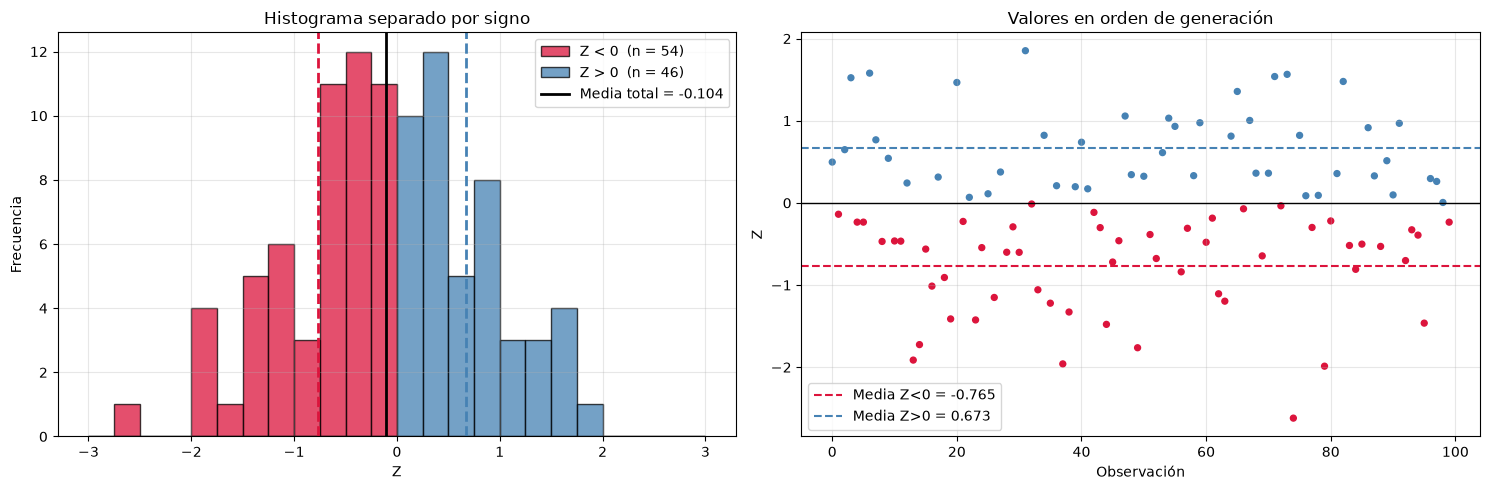

In [3]:
bins = np.linspace(-3, 3, 25)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(negativos, bins=bins, color="crimson", edgecolor="black", alpha=0.75,
             label=f"Z < 0  (n = {len(negativos)})")
axes[0].hist(positivos, bins=bins, color="steelblue", edgecolor="black", alpha=0.75,
             label=f"Z > 0  (n = {len(positivos)})")
axes[0].axvline(negativos.mean(), color="crimson", ls="--", lw=2)
axes[0].axvline(positivos.mean(), color="steelblue", ls="--", lw=2)
axes[0].axvline(Z.mean(), color="black", lw=2, label=f"Media total = {Z.mean():.3f}")
axes[0].set_title("Histograma separado por signo")
axes[0].set_xlabel("Z"); axes[0].set_ylabel("Frecuencia")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].scatter(np.arange(100), Z, c=np.where(Z < 0, "crimson", "steelblue"), s=18)
axes[1].axhline(0, color="black", lw=1)
axes[1].axhline(negativos.mean(), color="crimson", ls="--", label=f"Media Z<0 = {negativos.mean():.3f}")
axes[1].axhline(positivos.mean(), color="steelblue", ls="--", label=f"Media Z>0 = {positivos.mean():.3f}")
axes[1].set_title("Valores en orden de generación")
axes[1].set_xlabel("Observación"); axes[1].set_ylabel("Z")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Qué pasa si forzamos la simetría con antitéticas

In [4]:
Z_anti = np.concatenate([Z[:50], -Z[:50]])

print(f"Negativos: {(Z_anti < 0).sum()}   Positivos: {(Z_anti > 0).sum()}")
print(f"Media Z<0: {Z_anti[Z_anti < 0].mean():.4f}   Media Z>0: {Z_anti[Z_anti > 0].mean():.4f}")
print(f"Media total: {Z_anti.mean():.6f}")

Negativos: 50   Positivos: 50
Media Z<0: -0.7664   Media Z>0: 0.7664
Media total: -0.000000


## Un solo escenario con Z = 1

Antes de simular miles de trayectorias, vale la pena seguir paso a paso qué pasa en un solo escenario. Con $Z = 1$ el choque es de una desviación estándar hacia arriba:

$$S_T = S_0 \exp\left[\left(r - \tfrac{\sigma^2}{2}\right)T + \sigma\sqrt{T}\,Z\right]$$

### Parámetros

In [5]:
S0, K, r, sigma, T = 100, 100, 0.05, 0.20, 1
Z = 1

### Precio final y payoffs del escenario

In [6]:
ST = S0 * np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*Z)

payoff_call = max(ST - K, 0)
payoff_put  = max(K - ST, 0)

desc = np.exp(-r*T)

print(f"S_T                     : {ST:.4f}")
print(f"Payoff call             : {payoff_call:.4f}")
print(f"Payoff put              : {payoff_put:.4f}")
print(f"Call descontada a hoy   : {desc*payoff_call:.4f}")
print(f"Put descontada a hoy    : {desc*payoff_put:.4f}")

S_T                     : 125.8600
Payoff call             : 25.8600
Payoff put              : 0.0000
Call descontada a hoy   : 24.5988
Put descontada a hoy    : 0.0000


### Su escenario espejo: Z = −1

In [7]:
Z_anti = -Z
ST_anti = S0 * np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*Z_anti)

print(f"S_T                     : {ST_anti:.4f}")
print(f"Payoff call             : {max(ST_anti - K, 0):.4f}")
print(f"Payoff put              : {max(K - ST_anti, 0):.4f}")

S_T                     : 84.3665
Payoff call             : 0.0000
Payoff put              : 15.6335


### Promedio antitético del par: (opción(Z) + opción(−Z)) / 2

In [8]:
call_par = (max(ST - K, 0) + max(ST_anti - K, 0)) / 2
put_par  = (max(K - ST, 0) + max(K - ST_anti, 0)) / 2
ST_par   = (ST + ST_anti) / 2

print(f"S_T promedio del par    : {ST_par:.4f}   (E[S_T] teórico = {S0*np.exp(r*T):.4f})")
print(f"\nCall promedio del par   : {call_par:.4f}   descontada: {desc*call_par:.4f}")
print(f"Put promedio del par    : {put_par:.4f}   descontada: {desc*put_par:.4f}")

S_T promedio del par    : 105.1132   (E[S_T] teórico = 105.1271)

Call promedio del par   : 12.9300   descontada: 12.2994
Put promedio del par    : 7.8168   descontada: 7.4355


## Antitéticas con 10 valores de Z

Para cada $Z_i$ se calcula la call en su escenario y en su espejo, y se promedian:

$$\hat{C}_i = \frac{\text{call}(Z_i) + \text{call}(-Z_i)}{2}$$

El precio estimado es el promedio de esos 10 pares.

### Valores de Z

In [9]:
Z = np.array([0.07629, -0.2985, -0.7983, 0.993, -1.3465,
              1.2462, -1.1505, 0.7615, 0.2816, 0.81])

In [10]:
def precio_final(z):
    return S0 * np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*z)

desc = np.exp(-r*T)

call_z     = desc * np.maximum(precio_final(Z)  - K, 0)
call_menos = desc * np.maximum(precio_final(-Z) - K, 0)
call_par   = (call_z + call_menos) / 2

pd.DataFrame({
    "Z": Z,
    "S_T(Z)": precio_final(Z),
    "S_T(-Z)": precio_final(-Z),
    "call(Z)": call_z,
    "call(-Z)": call_menos,
    "Promedio del par": call_par
}).round(4)

,Z,S_T(Z),S_T(-Z),call(Z),call(-Z),Promedio del par
0,0.0763,104.6298,101.4851,4.4040,1.4127,2.9083
1,-0.2985,97.0737,109.3846,0.0000,8.9269,4.4635
2,-0.7983,87.8394,120.8839,0.0000,19.8653,9.9327
3,0.9930,125.6839,84.4847,24.4313,0.0000,12.2157
4,-1.3465,78.7179,134.8914,0.0000,33.1897,16.5949
5,1.2462,132.2125,80.3129,30.6414,0.0000,15.3207
6,-1.1505,81.8649,129.7060,0.0000,28.2572,14.1286
7,0.7615,119.9974,88.4883,19.0221,0.0000,9.5111
8,0.2816,109.0155,97.4023,8.5758,0.0000,4.2879
9,0.8100,121.1671,87.6341,20.1347,0.0000,10.0674


### Precio estimado: Monte Carlo simple vs antitéticas

In [11]:
print(f"Monte Carlo simple (solo Z)  : {call_z.mean():.4f}   desv. est. = {call_z.std(ddof=1):.4f}")
print(f"Antitéticas (pares Z, -Z)    : {call_par.mean():.4f}   desv. est. = {call_par.std(ddof=1):.4f}")
print(f"Black-Scholes                : 10.4506")

Monte Carlo simple (solo Z)  : 10.7209   desv. est. = 11.7690
Antitéticas (pares Z, -Z)    : 9.9431   desv. est. = 4.8021
Black-Scholes                : 10.4506
